# Active Subspaces of an Integrated Subsurface-Flow Model: Stream Discharge and Boundary Outflow of a Hillslope Catchment

__Daniel Erdal__ and __Olaf A. Cirpka__, Center for Applied Geosciences, University of Tübingen, Hölderlinstr. 12, 72074 Tübingen, Germany

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

**Summary.** Erdal and Cirpka [[1]](https://doi.org/10.5194/hess-23-3787-2019) ran 10,050 steady-state simulations of a three-dimensional, variably saturated HydroGeoSphere model of a catchment modelled on the Käsbach (Ammer valley, Germany) with 32 uncertain hydraulic, geological and boundary parameters, kept the 4,528 runs that meet five expert "behavioral" targets, and computed active subspaces from the gradients of a global quadratic fit. This notebook reproduces their analysis from the runs stored in the article's supplement: the stream discharge at gauge C and the net outflow across the subsurface boundaries have two-dimensional active subspaces dominated by the conductivities of the weathered Gipskeuper and the Muschelkalk, and the meta-model NSE values and activity scores of the paper's Figs. 4, 6, 8 and 9 are recovered to the precision the figures can be read. The subspaces describe the behavioral (posterior-like) sample, not the uniform prior box, and the notebook shows how much that matters.

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import active_subspaces as ac
import kaesbach_inputs as ki

SEED = 3787                     # the only seed in this notebook (all bootstraps)
t_start = time.perf_counter()
STORED_PER_YEAR = ki.RESIDENCE_PER_YEAR   # 17,520: Fig. 8 years = stored residence time / 17,520
                                          # (unit not stated by the authors; see DATA.md)

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ inputs with density $\rho$ on the normalized domain $[-1,1]^m$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T\rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. A large gap after the $n$-th eigenvalue means that $f$ changes mostly along the $n$ directions $\mathbf W_1$, so $f(\mathbf x)\approx g(\mathbf W_1^T\mathbf x)$, and a *sufficient summary plot* of $f$ against the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ shows the structure. The activity score $a_i = \sum_{j\le n}\lambda_j w_{ij}^2$ ranks the inputs as a global sensitivity measure. See Constantine [[2]](https://doi.org/10.1137/1.9781611973860).

### The model

HydroGeoSphere (Aquanty Inc., commercial) solves the three-dimensional Richards equation (paper Eq. 1, p. 3789)

$$S_s S_w(h)\frac{\partial h}{\partial t} + S_w(h)\,\theta_S\frac{\partial S_w(h)}{\partial t} = \nabla\cdot\big(\mathbf K_s k_r(h)\nabla(h+z)\big) + Q,$$

with the Mualem–van Genuchten retention and relative permeability (Eqs. 2–3), $S_e = [1+(\alpha|h|)^n]^{-(1-1/n)}$ for $h<0$ and $k_r = S_e^{1/2}\,[1-(1-S_e^{1/(1-1/n)})^{1-1/n}]^2$. The domain (about 4 km × 6 km, 1,001,760 prism elements) has five homogeneous geological units, from the bottom up the Upper Muschelkalk limestone (mo), the Lettenkeuper (ku), the Gipskeuper (km1), its weathering zone (km1-w) and Quaternary valley fill (Q), cut by a north–south fault. Boundaries: a Dirichlet head at the bottom (from a regional model, offset by a parameter), drains for the streams and, 0.2 m above ground, for flooding, a Cauchy boundary on the southern wall, and land-use dependent recharge on top. The model is run in transient mode with constant forcing until steady state (p. 3792); one run costs about 9.6 CPU hours (96,000 CPU hours for 10,000 runs, p. 3793), so the model cannot be rerun here and the stored runs are all we have.

**Quantities of interest** (all in the supplement; units in `DATA.md`): top-drain flooding, discharge at gauge C, flows in streams A and B (m$^3$/s), the ratio of stream discharge to recharge, the net outflow across the bottom and side boundaries (m$^3$/s), and particle residence times in ku, km1 and km1-w (unit not stated by the authors: the paper's Fig. 8, in years, equals the stored values divided by 17,520, so the stored unit is probably half-hours; see the Fig. 8 section). We study the paper's two sensitivity targets of Fig. 6, **discharge at gauge C** and **net boundary outflow**, and check the residence times against Fig. 8.

**Inputs.** The 32 inputs are uniform within the bounds of Table 1 (p. 3794). The supplement stores each input as a coordinate $u\in[0,1]$. Comparing the stored marginals with the paper's Fig. 3 (p. 3796), which shows nine inputs on physical axes, shows that the five conductivities are log-uniform and stored reversed ($u=1$ is the lower bound), and the other four of Fig. 3 are linear. For the remaining inputs the map is assumed (column `map` below; details in `DATA.md`). The analysis does not depend on that choice: every analysis coordinate below is an affine function of the stored $u$.

In [2]:
print(f"{'#':>2s} {'name':22s} {'units':6s} {'lower':>9s} {'upper':>9s} {'scale':6s} {'stored u':9s} map")
for j in range(32):
    print(f"{j:2d} {ki.NAMES[j]:22s} {ki.UNITS[j]:6s} {ki.LOWER[j]:9.3g} {ki.UPPER[j]:9.3g} "
          f"{ki.SCALE[j]:6s} {'1 - frac' if ki.REVERSED[j] else 'frac':9s} {ki.STATUS[j]}")

 # name                   units      lower     upper scale  stored u  map
 0 bottom_head_offset     m             -5         5 linear frac      verified
 1 fault_offset           m              0       100 linear frac      verified
 2 contact_offset_ku_km1  m            -20        20 linear frac      assumed
 3 km1w_thickness         m              5        50 linear frac      verified
 4 K_km1w                 m/s        1e-07     5e-05 log    1 - frac  verified
 5 aniso_km1w             -              1        50 linear frac      sign checked
 6 K_ku                   m/s        1e-08     1e-05 log    1 - frac  verified
 7 aniso_ku               -              1        50 linear frac      assumed
 8 K_km1                  m/s        1e-09     1e-07 log    1 - frac  verified
 9 aniso_km1              -              1        50 linear frac      assumed
10 K_mo                   m/s        1e-07     1e-05 log    1 - frac  verified
11 K_Q                    m/s        1e-07     1e-05 log

### Load the data

`inputs.csv` holds the inputs in physical units (computed from the stored coordinates by `kaesbach_inputs.to_physical`), `inputs_unit.csv` the coordinates exactly as stored, and `outputs.csv` the nine outputs exactly as stored. The cell converts physical inputs to analysis coordinates once: $\ln x$ for the log-uniform inputs, $x$ otherwise. The input space is uniform on these coordinates, and v1 maps them to $[-1,1]$, which is the paper's Eq. (4) (with the sign of the conductivity coordinates flipped, which changes no eigenvalue or activity score).

In [3]:
X = np.loadtxt('inputs.csv', delimiter=',')        # (10050, 32) physical units
U = np.loadtxt('inputs_unit.csv', delimiter=',')   # (10050, 32) as stored by the authors, u in [0, 1]
Y = np.loadtxt('outputs.csv', delimiter=',')       # (10050, 9) as stored by the authors
print('X', X.shape, ' U', U.shape, ' Y', Y.shape)
print(f'physical -> stored coordinate, max |difference| = {np.abs(ki.to_unit(X) - U).max():.1e}')

# The one unit conversion of the notebook: analysis coordinates are ln(x) for the
# log-uniform inputs (conductivities, specific storage) and x for the others.
Z = ki.to_analysis(X)
lo, hi = ki.analysis_bounds()
space = ac.Uniform(lo, hi, names=ki.NAMES)
Xn = space.to_normalized(Z)                         # the paper's scaled inputs, Eq. (4), up to sign
print(f'normalized inputs in [{Xn.min():.4f}, {Xn.max():.4f}]; '
      f'|Xn - (2u - 1)| for unreversed, |Xn + (2u - 1)| for reversed columns: '
      f'{np.abs(Xn - np.where(ki.REVERSED, -1, 1) * (2 * U - 1)).max():.1e}')

X (10050, 32)  U (10050, 32)  Y (10050, 9)


physical -> stored coordinate, max |difference| = 1.6e-15
normalized inputs in [-1.0000, 1.0000]; |Xn - (2u - 1)| for unreversed, |Xn + (2u - 1)| for reversed columns: 3.0e-15


### The sample and the behavioral runs

The runs are not a sample of the uniform box. The first 500 rows are the paper's initial Latin hypercube (step 1, p. 3791). The other rows were proposed from the prior and pre-screened ("stage one") with cubic meta-models on two-dimensional active subspaces, accepting a proposal if the meta-models predicted all five targets on the permitted side, with a soft margin, or with 10% probability regardless (step 4, p. 3791). The sensitivity analysis then uses only the runs that meet all five targets after the full model run ("stage two"): each target must be on the permitted side of the midpoint between its limit and its outer point (pp. 3793–3795). We apply that rule with the thresholds hard-coded in the supplement's app.

In [4]:
acc = ki.behavioral(Y)
crit = {'flooding <= 3e-3 m^3/s': Y[:, 0] <= 3e-3, 'gauge C >= 4e-3 m^3/s': Y[:, 1] >= 4e-3,
        'stream A <= 1.5e-3 m^3/s': Y[:, 2] <= 1.5e-3, 'stream B >= 7.5e-7 m^3/s': Y[:, 3] >= 7.5e-7,
        '0.225 <= ratio <= 0.67': (Y[:, 4] >= 0.225) & (Y[:, 4] <= 0.67)}
for k, c in crit.items():
    print(f'{k:26s} met by {c.sum():5d} of {len(Y)} runs')
print(f'all five (behavioral, stage-two accepted): {acc.sum()} runs; paper: 4533')
strict = ((Y[:, 0] < 3e-3) & (Y[:, 1] > 4e-3) & (Y[:, 2] < 1.5e-3) & (Y[:, 3] > 7.5e-7)
          & (Y[:, 4] > 0.225) & (Y[:, 4] < 0.67)).sum()
alt = ((Y[:, 0] <= 3e-3) & (Y[:, 1] >= 4e-3) & (Y[:, 2] <= 1.5e-3) & (Y[:, 3] >= 7.5e-7)
       & (Y[:, 4] >= 0.225) & (Y[:, 4] <= 0.675)).sum()
print(f'variants: strict inequalities {strict}; ratio <= 0.675 (the paper\'s midpoint) {alt}; '
      f'first 10000 rows only {acc[:10000].sum()}')
print(f'rows 1-500: {acc[:500].sum()} behavioral; rows 501-10050: {acc[500:].sum()} of 9550')

# Can the paper's 4533 come from a subset of the stored runs? Any subset has at most the count over
# all rows; every window of 10000 consecutive rows has fewer still.
win = [acc[s:s + 10000].sum() for s in range(len(Y) - 10000 + 1)]
print(f'behavioral runs in each window of 10000 consecutive rows: {min(win)} to {max(win)}')
def n_beh(Yv, lim):
    return int(((Yv[:, 0] <= lim[0]) & (Yv[:, 1] >= lim[1]) & (Yv[:, 2] <= lim[2]) & (Yv[:, 3] >= lim[3])
                & (Yv[:, 4] >= lim[4]) & (Yv[:, 4] <= lim[5])).sum())
lim0 = [3e-3, 4e-3, 1.5e-3, 7.5e-7, 0.225, 0.67]
loosen = [1, -1, 1, -1, -1, 1]                    # +1: raise the limit, -1: lower it (admits more runs)
for i, lab in enumerate(['flooding', 'gauge C', 'stream A', 'stream B', 'lower ratio', 'upper ratio']):
    hit = None
    for fac in 1 + np.arange(1, 1001) * 1e-4:     # loosen one limit by up to 10%
        lim = list(lim0); lim[i] = lim0[i] * fac ** loosen[i]
        if n_beh(Y, lim) >= 4533:
            hit = (fac, lim[i], n_beh(Y, lim)); break
    print(f'    loosening only the {lab} limit: ' +
          (f'{lim0[i]:.4g} -> {hit[1]:.5g} (factor {hit[0]:.4f}) gives {hit[2]}' if hit
           else 'no change up to 10% reaches 4533'))
print(f'all outputs rounded to 6 decimals: {n_beh(np.round(Y, 6), lim0)} behavioral runs')

# rows 1-500 are the initial Latin hypercube: occupied strata of width 1/500 per input
strata = [len(np.unique(np.floor(U[:500, j] * 500))) for j in range(32)]
print(f'rows 1-500: occupied strata per input min {min(strata)}, max {max(strata)} of 500')

# outputs at a bound or with an unexpected sign
print('exact zeros per output (all runs):', dict(zip(ki.OUTPUT_NAMES, (Y == 0).sum(0).tolist())))
print('negative zeros (-0.0) per output:', dict(zip(ki.OUTPUT_NAMES, (np.signbit(Y) & (Y == 0)).sum(0).tolist())))
print(f'net boundary outflow < 0 (net inflow): {(Y[:, 5] < 0).sum()} run(s), {(Y[acc, 5] < 0).sum()} behavioral')
print(f'zeros among behavioral runs: flooding {(Y[acc, 0] == 0).sum()}, stream A {(Y[acc, 2] == 0).sum()}, '
      f'gauge C {(Y[acc, 1] == 0).sum()}')

flooding <= 3e-3 m^3/s     met by  6897 of 10050 runs
gauge C >= 4e-3 m^3/s      met by  8829 of 10050 runs
stream A <= 1.5e-3 m^3/s   met by  8852 of 10050 runs
stream B >= 7.5e-7 m^3/s   met by  8971 of 10050 runs
0.225 <= ratio <= 0.67     met by  6987 of 10050 runs
all five (behavioral, stage-two accepted): 4528 runs; paper: 4533
variants: strict inequalities 4528; ratio <= 0.675 (the paper's midpoint) 4528; first 10000 rows only 4499
rows 1-500: 10 behavioral; rows 501-10050: 4518 of 9550
behavioral runs in each window of 10000 consecutive rows: 4499 to 4527
    loosening only the flooding limit: 0.003 -> 0.0030051 (factor 1.0017) gives 4533
    loosening only the gauge C limit: 0.004 -> 0.0038245 (factor 1.0459) gives 4533
    loosening only the stream A limit: 0.0015 -> 0.0015056 (factor 1.0037) gives 4533


    loosening only the stream B limit: no change up to 10% reaches 4533
    loosening only the lower ratio limit: 0.225 -> 0.22478 (factor 1.0010) gives 4533
    loosening only the upper ratio limit: no change up to 10% reaches 4533
all outputs rounded to 6 decimals: 4531 behavioral runs
rows 1-500: occupied strata per input min 499, max 499 of 500
exact zeros per output (all runs): {'flooding': 393, 'discharge_gauge_C': 24, 'flow_stream_A': 1089, 'flow_stream_B': 1062, 'ratio_stream_to_recharge': 4, 'net_boundary_outflow': 0, 'residence_time_ku': 0, 'residence_time_km1': 0, 'residence_time_km1w': 0}
negative zeros (-0.0) per output: {'flooding': 393, 'discharge_gauge_C': 24, 'flow_stream_A': 1089, 'flow_stream_B': 1062, 'ratio_stream_to_recharge': 4, 'net_boundary_outflow': 0, 'residence_time_ku': 0, 'residence_time_km1': 0, 'residence_time_km1w': 0}
net boundary outflow < 0 (net inflow): 1 run(s), 0 behavioral
zeros among behavioral runs: flooding 137, stream A 340, gauge C 0


The rule gives 4,528 behavioral runs, 5 fewer than the 4,533 in the paper (p. 3795); strict inequalities or the paper's midpoint 0.675 for the upper ratio limit give the same 4,528. No subset of the stored runs can give 4,533: the count over all 10,050 rows is already below it, and every window of 10,000 consecutive rows gives 4,499 to 4,527. The paper's count must come from different output values or thresholds, and the data show no clean cause: loosening one limit reaches 4,533 only through small, arbitrary changes (flooding 3e-3 to 3.0051e-3, stream A 1.5e-3 to 1.5056e-3, lower ratio 0.225 to 0.22478) or a large one (gauge C 4e-3 to 3.8245e-3); the stream-B and upper-ratio limits cannot reach it within 10%, and rounding all outputs to 6 decimals gives 4,531. We leave the difference unresolved. Only 10 of the 500 Latin hypercube runs are behavioral, against 4,518 of the 9,550 pre-screened runs, which shows how much the pre-screening concentrated the sample. Each input of rows 1–500 occupies 499 of the 500 strata of width 1/500, so these rows are a Latin hypercube up to one point. The supplement holds 10,050 rows, 50 more than the 10,000 runs of the paper. Zero flows are stored as $-0$ (393 flooding, 24 gauge C, 1,089 stream A, 1,062 stream B and 4 ratio values); they are physical (drains that do not flow) and are kept. One run has a negative net boundary outflow (a net inflow, physically possible); it is not behavioral.

The next cell measures how far the behavioral sample is from uniform, in the analysis coordinates (fraction of each range, conductivities increasing).

In [5]:
from scipy import stats
print(f"{'input':22s} {'mean u, rows 1-500':>18s} {'behavioral':>11s} {'KS p, behavioral vs U(0,1)':>27s}")
for j in [0, 1, 3, 4, 6, 8, 10, 11, 28]:
    x = (Xn[:, j] + 1) / 2                          # fraction of the range in the analysis coordinate
    print(f'{ki.NAMES[j]:22s} {x[:500].mean():18.3f} {x[acc].mean():11.3f} '
          f'{stats.kstest(x[acc], "uniform").pvalue:27.1e}')
print(f'mean of all stored u over the behavioral runs: {U[acc].mean():.4f}')

input                  mean u, rows 1-500  behavioral  KS p, behavioral vs U(0,1)
bottom_head_offset                  0.501       0.638                    5.9e-209
fault_offset                        0.499       0.317                     0.0e+00
km1w_thickness                      0.502       0.710                     0.0e+00
K_km1w                              0.500       0.901                     0.0e+00
K_ku                                0.500       0.687                     0.0e+00
K_km1                               0.501       0.552                     2.2e-29
K_mo                                0.501       0.233                     0.0e+00
K_Q                                 0.501       0.681                    3.8e-300
cauchy_head                         0.501       0.563                     4.1e-46
mean of all stored u over the behavioral runs: 0.4851


The behavioral runs prefer a conductive weathered Gipskeuper (mean fraction 0.901 of the $\ln K$ range), a poorly conductive Muschelkalk (0.233), a thick weathering zone (0.710), small fault offsets (0.317) and a high bottom head (0.638), the patterns of the paper's Fig. 3; Kolmogorov–Smirnov tests reject uniformity with $p$ below $10^{-28}$ for all nine inputs. The active subspaces below are therefore those of $f$ under this behavioral density $\rho$ (paper p. 3797: "the red bars in Fig. 3 define the probability density ρ considered in Eq. (5)"). The mean stored coordinate over the behavioral runs is 0.4851, which matters for the scaling question below.

The helper functions implement the paper's three gradient fits (Eqs. 9–11), the eigendecomposition of Eq. (7), and the NSE of its cubic meta-model in the active variables (Eqs. 13–14).

In [6]:
m = 32
ju, ku = np.triu_indices(m, 1)

def design(Xn, fit):
    """Regressors of the paper's gradient fits (Eqs. 9-11): 1 full quadratic,
    2 quadratic without cross terms, 3 linear."""
    cols = [np.ones((len(Xn), 1)), Xn]
    if fit in (1, 2):
        cols.append(Xn ** 2)
    if fit == 1:
        cols.append(Xn[:, ju] * Xn[:, ku])
    return np.hstack(cols)

def fit_gradients(Xn, f, fit):
    """Least-squares polynomial fit in the normalized inputs; returns its gradients
    at the samples (normalized coordinates) and its in-sample R^2."""
    A = design(Xn, fit)
    c = np.linalg.solve(A.T @ A, A.T @ f)           # normal equations, as in the paper's app
    G = np.tile(c[1:m + 1], (len(Xn), 1))
    if fit in (1, 2):
        G += 2 * Xn * c[m + 1:2 * m + 1]
    if fit == 1:
        H = np.zeros((m, m))
        H[ju, ku] = c[2 * m + 1:]
        G += Xn @ (H + H.T)
    r2 = 1 - np.sum((A @ c - f) ** 2) / np.sum((f - f.mean()) ** 2)
    return G, r2

def eig_C(G):
    lam, W = np.linalg.eigh(G.T @ G / len(G))
    i = np.argsort(lam)[::-1]
    return lam[i], W[:, i]

def cubic_nse(y, f):
    """NSE (in-sample R^2) of the paper's meta-model, a full cubic in one or two active variables (Eq. 13)."""
    y = np.atleast_2d(y.T).T
    if y.shape[1] == 1:
        A = np.column_stack([y[:, 0] ** k for k in range(4)])
    else:
        a, b = y[:, 0], y[:, 1]
        A = np.column_stack([np.ones_like(a), a, b, a * a, a * b, b * b, a ** 3, a * a * b, a * b * b, b ** 3])
    c, *_ = np.linalg.lstsq(A, f, rcond=None)
    return 1 - np.sum((A @ c - f) ** 2) / np.sum((f - f.mean()) ** 2)

def nse_two(Xn, f, fit):
    G, _ = fit_gradients(Xn, f, fit)
    lam, W = eig_C(G)
    return cubic_nse(Xn @ W[:, :(1 if fit == 3 else 2)], f)

**Check: the paper's Fig. 4.** Fig. 4 gives the meta-model NSE for three targets (flooding, ratio, stream A) after the first 500, the first 1000 and all runs, before the behavioral filter. The paper uses gradient fit 2 when there are fewer runs than about twice the 561 coefficients of fit 1 (p. 3790).

In [7]:
paper_fig4 = {500: (0.76, 0.75, 0.56), 1000: (0.83, 0.72, 0.65), len(Y): (0.81, 0.74, 0.70)}
print('first N rows   gradient fit   NSE: flooding  ratio  stream A    paper Fig. 4')
for N, (pa, pb, pc) in paper_fig4.items():
    fit = 2 if N < 1122 else 1          # fewer runs than twice the 561 coefficients -> fit 2 (p. 3790)
    v = [nse_two(Xn[:N], Y[:N, k], fit) for k in (0, 4, 2)]
    print(f'{N:12d}   {fit:12d}   {v[0]:14.3f} {v[1]:6.3f} {v[2]:9.3f}    {pa:.2f}, {pb:.2f}, {pc:.2f}')

first N rows   gradient fit   NSE: flooding  ratio  stream A    paper Fig. 4
         500              2            0.762  0.748     0.561    0.76, 0.75, 0.56
        1000              2            0.825  0.715     0.655    0.83, 0.72, 0.65


       10050              1            0.812  0.745     0.699    0.81, 0.74, 0.70


All nine NSE values agree with Fig. 4 to the two printed digits (0.745 against 0.74 and 0.655 against 0.65 sit on the rounding boundary), which confirms that the rows are stored in sampling order, that the analysis coordinates are the paper's up to sign, and that fit 2 was used for 500 and 1000 runs. The last row uses all 10,050 rows; the paper says 10,000.

### Estimate the subspace

The paper has no model gradients. Its standard estimate (gradient fit 1, p. 3790) fits a full quadratic $q(\tilde{\mathbf x}) = b_0 + \sum_i b_i\tilde x_i + \sum_{i\le j} b_{ij}\tilde x_i\tilde x_j$ (561 coefficients) by least squares to the behavioral runs and averages $\nabla q\,\nabla q^T$ over the same runs (Eq. 7). We do the same: 4,528 runs, 8.1 per coefficient, above twice the coefficient count (1,122). The gradients of $q$, converted to the analysis coordinates, are passed to v1's gradient estimator (`"as"`) with 500 bootstrap replicates and `SEED`.

**What this estimator is.** Because $\nabla q(\tilde{\mathbf x}) = \mathbf g + \mathbf H\tilde{\mathbf x}$ is affine, the averaged matrix is $\mathbf C = \mathbf g\mathbf g^T + \mathbf g\boldsymbol\mu^T\mathbf H + \mathbf H\boldsymbol\mu\mathbf g^T + \mathbf H\mathbf S\mathbf H$, with $\boldsymbol\mu$ and $\mathbf S$ the mean and second-moment matrix of the behavioral runs. It is the QPHD construction (a global quadratic fit, then $\mathbf C$ in closed form) with the moments of the behavioral sample in place of those of the uniform box; the next cell checks the identity numerically. All of the information in $\mathbf C$ is in the 561 regression coefficients: the 4,528 gradient rows are not 4,528 independent gradient samples. We do not use v1's `"qphd"` for the main result because it uses the moments of the uniform box ($\boldsymbol\mu = 0$, $\mathbf S = \mathbf I/3$), i.e. it averages over the prior and not over the behavioral runs (compared at the end).

**Two bootstraps.** (i) v1's bootstrap resamples the 4,528 gradient rows with the quadratic held fixed, so its intervals show the Monte Carlo error of the average only. (ii) A *refit bootstrap* (500 replicates, `SEED`) resamples the behavioral runs with replacement, refits the quadratic and recomputes $\mathbf C$; this is the sampling uncertainty of the estimate, and it is the one to read. The plots show both, labelled. The paper's subsample study (Fig. 9, repeated further down) is a third, different measure. The eigenvalues are those of the fitted quadratic, which explains the stored $f$ with in-sample $R^2$ 0.815 (gauge C) and 0.875 (net outflow); the rest of $f$ does not enter $\mathbf C$. Following the paper we keep $n = 2$ (p. 3791). Eigenvector signs are set so that $f$ increases along $\mathbf w_1$ and $\mathbf w_2$; the paper shows no eigenvectors.

In [8]:
Xa, Za, Ua = Xn[acc], Z[acc], U[acc]
qois = {'discharge_gauge_C': 1, 'net_boundary_outflow': 5}
subs, G_phys, r2q = {}, {}, {}
half = (hi - lo) / 2
for name, k in qois.items():
    f = Y[acc, k]
    G, r2q[name] = fit_gradients(Xa, f, fit=1)          # gradient fit 1: full quadratic, 561 coefficients
    G_phys[name] = G / half                             # d f / d z, physical (analysis) coordinates
    sub = ac.active_subspace(space=space, X=Za, grads=G_phys[name], estimator='as', n=2,
                             nboot=500, bootstrap_vectors=2, rng=SEED, qoi=name)
    subs[name] = ac.orient(sub, by='covariance', X=Za, f=f, columns=2)
    lam = subs[name].eigenvalues
    print(f'{name}: M = {acc.sum()}, quadratic in-sample R^2 = {r2q[name]:.3f}, '
          f'lambda_1..4 = {np.array2string(lam[:4], precision=3)}, '
          f'lambda1/lambda2 = {lam[0] / lam[1]:.2f}, lambda2/lambda3 = {lam[1] / lam[2]:.2f}')
    print(f'    first two eigenvalues hold {lam[:2].sum() / lam.sum():.1%} of the trace; '
          f'EVG gap rule picks n = {ac.dimension_criterion(subs[name], rule="evg")[2]}')

def quad_g_H(X, F):
    # Gradient fit 1 for every column of F at once: grad q(x) = g + H x; returns (g, H) per column.
    A = design(X, 1)
    coef = np.linalg.solve(A.T @ A, A.T @ F)
    out = []
    for c in coef.T:
        H = np.diag(2 * c[m + 1:2 * m + 1])
        H[ju, ku] = H[ku, ju] = c[2 * m + 1:]
        out.append((c[1:m + 1], H))
    return out

# What the estimator is: with grad q = g + H x, the average of grad q grad q^T over the runs equals
# g g^T + g mu^T H + H mu g^T + H S H (mu, S: mean and second moment of the behavioral runs), i.e.
# QPHD with the moments of the behavioral sample in place of those of the uniform box.
Fq = Y[acc][:, list(qois.values())]
mu, S2 = Xa.mean(0), Xa.T @ Xa / len(Xa)
for (name, k), (g, H) in zip(qois.items(), quad_g_H(Xa, Fq)):
    Cq = np.outer(g, g) + np.outer(g, H @ mu) + np.outer(H @ mu, g) + H @ S2 @ H
    Cg = G_phys[name] * half
    Cg = Cg.T @ Cg / len(Cg)
    print(f'{name}: ||C_QPHD(behavioral mean and second moment) - mean(grad q grad q^T)|| / ||C|| = '
          f'{np.linalg.norm(Cq - Cg) / np.linalg.norm(Cg):.1e}')

# Refit bootstrap: resample the behavioral RUNS with replacement, refit the quadratic, recompute C.
# (v1's bootstrap above resamples the gradient rows of one fixed quadratic: Monte Carlo error only.)
NREFIT = 500
rng_refit = np.random.default_rng(SEED)
refit_lam = {nm: np.empty((NREFIT, m)) for nm in qois}
refit_dist = {nm: np.empty((NREFIT, 8)) for nm in qois}
t0 = time.perf_counter()
for b in range(NREFIT):
    idx = rng_refit.integers(0, len(Xa), len(Xa))
    for nm, (g, H) in zip(qois, quad_g_H(Xa[idx], Fq[idx])):
        lam_b, W_b = eig_C(g + Xa[idx] @ H)
        refit_lam[nm][b] = lam_b
        refit_dist[nm][b] = [np.linalg.norm(subs[nm].W[:, :j].T @ W_b[:, j:], 2) for j in range(1, 9)]
print(f'refit bootstrap: {NREFIT} replicates in {time.perf_counter() - t0:.0f} s')
pr = lambda r: f'[{np.percentile(r, 2.5):.2f}, {np.percentile(r, 97.5):.2f}]'
for nm in qois:
    L, Lv = refit_lam[nm], subs[nm].bootstrap_eigenvalues
    print(f'{nm}, 95% intervals: lambda1/lambda2 refit {pr(L[:, 0] / L[:, 1])}, quadratic fixed (v1) '
          f'{pr(Lv[:, 0] / Lv[:, 1])}; lambda2/lambda3 refit {pr(L[:, 1] / L[:, 2])}, fixed {pr(Lv[:, 1] / Lv[:, 2])}')
    print(f'    mean subspace distance n = 1, 2, 3: refit {np.round(refit_dist[nm][:, :3].mean(0), 4)}, '
          f'quadratic fixed (v1) {np.round(subs[nm].bootstrap_distances[:, :3].mean(0), 4)}')

discharge_gauge_C: M = 4528, quadratic in-sample R^2 = 0.815, lambda_1..4 = [2.376e-04 5.139e-05 1.614e-05 5.101e-06], lambda1/lambda2 = 4.62, lambda2/lambda3 = 3.18
    first two eigenvalues hold 91.3% of the trace; EVG gap rule picks n = 1


net_boundary_outflow: M = 4528, quadratic in-sample R^2 = 0.875, lambda_1..4 = [5.016e-04 7.600e-05 2.411e-05 6.634e-06], lambda1/lambda2 = 6.60, lambda2/lambda3 = 3.15
    first two eigenvalues hold 92.8% of the trace; EVG gap rule picks n = 1
discharge_gauge_C: ||C_QPHD(behavioral mean and second moment) - mean(grad q grad q^T)|| / ||C|| = 3.8e-13
net_boundary_outflow: ||C_QPHD(behavioral mean and second moment) - mean(grad q grad q^T)|| / ||C|| = 2.2e-13


refit bootstrap: 500 replicates in 38 s
discharge_gauge_C, 95% intervals: lambda1/lambda2 refit [4.07, 5.28], quadratic fixed (v1) [4.34, 4.89]; lambda2/lambda3 refit [2.54, 3.75], fixed [2.99, 3.40]
    mean subspace distance n = 1, 2, 3: refit [0.0251 0.0687 0.0875], quadratic fixed (v1) [0.0079 0.0139 0.0151]
net_boundary_outflow, 95% intervals: lambda1/lambda2 refit [5.87, 7.32], quadratic fixed (v1) [6.20, 6.96]; lambda2/lambda3 refit [2.56, 3.64], fixed [2.97, 3.37]
    mean subspace distance n = 1, 2, 3: refit [0.0194 0.0602 0.0784], quadratic fixed (v1) [0.0069 0.0141 0.0161]


### Results: discharge at gauge C

95% refit bootstrap: lambda_1 [2.247e-04, 2.555e-04]; lambda_2 [4.484e-05, 6.023e-05]; lambda_3 [1.473e-05, 1.957e-05]; lambda1/lambda2 [4.07, 5.28]
95% quadratic fixed (v1): lambda_1 [2.332e-04, 2.422e-04]; lambda_2 [4.912e-05, 5.435e-05]; lambda_3 [1.555e-05, 1.674e-05]; lambda1/lambda2 [4.34, 4.89]


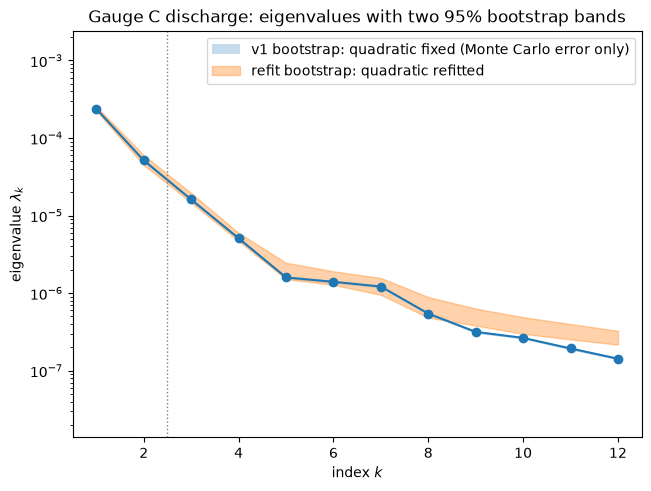

In [9]:
sub = subs['discharge_gauge_C']
fig, ax = ac.plotting.plot_eigenvalues(sub, k_max=12)
ax.collections[0].set_label('v1 bootstrap: quadratic fixed (Monte Carlo error only)')
qr = np.percentile(refit_lam['discharge_gauge_C'][:, :12], [2.5, 97.5], axis=0)
ax.fill_between(np.arange(1, 13), qr[0], qr[1], color='tab:orange', alpha=0.35,
                label='refit bootstrap: quadratic refitted')
ax.legend(loc='upper right')
ax.set_title('Gauge C discharge: eigenvalues with two 95% bootstrap bands')
iv = ac.bootstrap_interval(sub.bootstrap_eigenvalues)
ivr = np.percentile(refit_lam['discharge_gauge_C'], [2.5, 97.5], axis=0)
for lab, a, B_ in [('refit bootstrap', ivr, refit_lam['discharge_gauge_C']),
                   ('quadratic fixed (v1)', iv, sub.bootstrap_eigenvalues)]:
    print(f'95% {lab}: ' + '; '.join(f'lambda_{k + 1} [{a[0, k]:.3e}, {a[1, k]:.3e}]' for k in range(3))
          + f'; lambda1/lambda2 {pr(B_[:, 0] / B_[:, 1])}')
plt.close(fig)
fig

$\lambda_1/\lambda_2 = 4.62$ and $\lambda_2/\lambda_3 = 3.18$; the first two eigenvalues hold 91.3% of the trace, and the relative difference between $\mathbf C$ written as QPHD with the behavioral moments and the average of $\nabla q\,\nabla q^T$ is 3.8e-13 (2.2e-13 for the net outflow). With the quadratic refitted in each replicate, the 95% intervals are [4.07, 5.28] for $\lambda_1/\lambda_2$ and [2.54, 3.75] for $\lambda_2/\lambda_3$, and $\lambda_2$ lies in [4.484e-05, 6.023e-05]. With the quadratic held fixed (v1's bootstrap, Monte Carlo error only) the intervals are narrower: [4.34, 4.89], [2.99, 3.40] and [4.912e-05, 5.435e-05]. The two refit ratio intervals do not overlap, so the larger gap is after $\lambda_1$: v1's eigenvalue-gap rule picks $n = 1$, while the paper keeps two active variables because the second one visibly improves the meta-model (see the NSE values below).

mean subspace distance, n = 1, 2, 3: refit [0.0251 0.0687 0.0875] ; quadratic fixed (v1) [0.0079 0.0139 0.0151]
refit 97.5% point of the distance, n = 1, 2: [0.0407 0.1234]


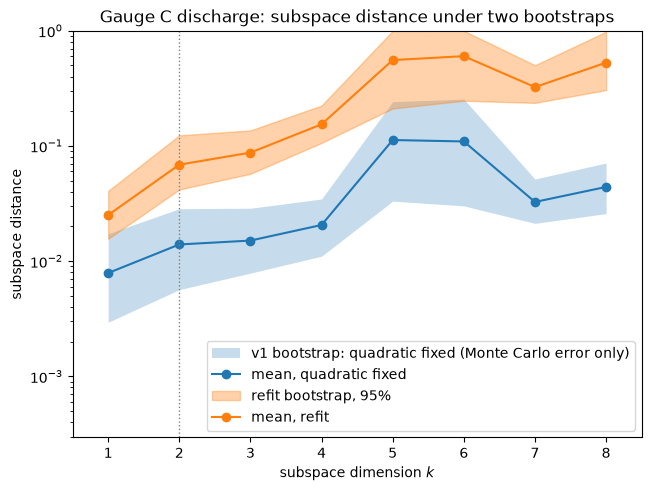

In [10]:
fig, ax = ac.plotting.plot_subspace_errors(sub, k_max=8)
ax.collections[0].set_label('v1 bootstrap: quadratic fixed (Monte Carlo error only)')
ax.lines[0].set_label('mean, quadratic fixed')
dR = refit_dist['discharge_gauge_C']
qd = np.percentile(dR, [2.5, 97.5], axis=0)
ax.fill_between(np.arange(1, 9), qd[0], qd[1], color='tab:orange', alpha=0.35, label='refit bootstrap, 95%')
ax.plot(np.arange(1, 9), dR.mean(0), 'o-', color='tab:orange', label='mean, refit')
ax.legend(loc='lower right')
ax.set_title('Gauge C discharge: subspace distance under two bootstraps')
print('mean subspace distance, n = 1, 2, 3: refit', np.round(dR[:, :3].mean(0), 4),
      '; quadratic fixed (v1)', np.round(sub.bootstrap_distances[:, :3].mean(0), 4))
print('refit 97.5% point of the distance, n = 1, 2:', np.round(qd[1, :2], 4))
plt.close(fig)
fig

With the quadratic refitted, the mean subspace distances are 0.0251 for $n=1$, 0.0687 for $n=2$ and 0.0875 for $n=3$, three to six times the values with the quadratic held fixed (0.0079, 0.0139, 0.0151), which measure only the Monte Carlo error of averaging one fitted quadratic. The refit values are the sampling uncertainty of the estimate: the first direction is well determined (97.5% point 0.0407), the two-dimensional subspace less so (97.5% point 0.1234), still far below the distance of 1 between unrelated subspaces.

w1: K_mo -0.671, K_km1w +0.582, bottom_head_offset +0.379, fault_offset -0.183, recharge_grass +0.112
w2: K_ku +0.774, fault_offset +0.548, aniso_ku -0.199, K_mo -0.151, km1w_thickness +0.145


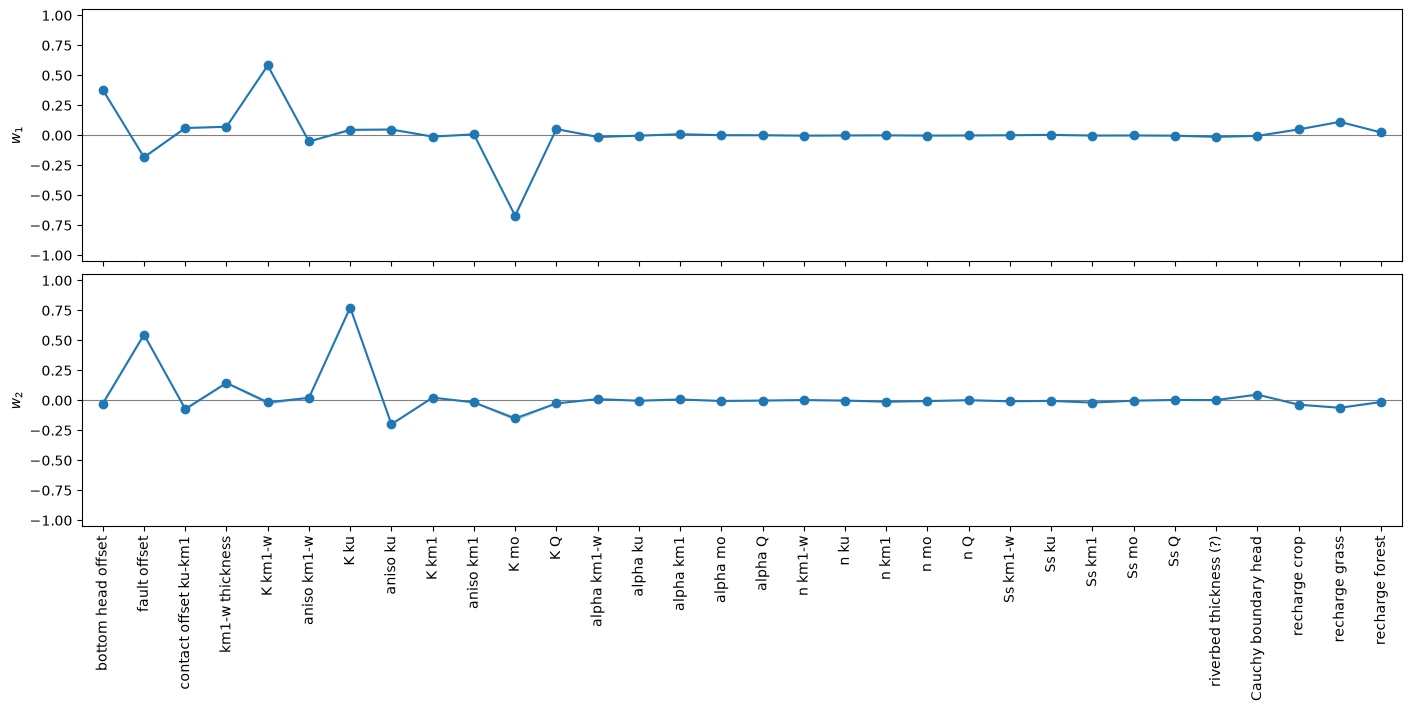

In [11]:
fig, axes = ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=ki.LABELS, interval='percentile',
                                          figsize=(14, 7))
for ax in axes:
    ax.tick_params(axis='x', labelrotation=90)
for j in range(2):
    w = sub.W[:, j]
    top = np.argsort(-np.abs(w))[:5]
    print(f'w{j + 1}: ' + ', '.join(f'{ki.NAMES[i]} {w[i]:+.3f}' for i in top))
plt.close(fig)
fig

$\mathbf w_1$ is mainly the Muschelkalk conductivity ($-0.671$), the weathered-Gipskeuper conductivity ($+0.582$) and the bottom head offset ($+0.379$): the discharge at gauge C grows when more water is routed through the conductive top layer to the streams and less leaves through the deep limestone and the bottom boundary, which is the partitioning the paper describes (p. 3797). $\mathbf w_2$ is mainly the Lettenkeuper conductivity ($+0.774$) and the fault offset ($+0.548$), the two inputs that set how much water the Lettenkeuper carries.

NSE of a cubic in y1: 0.532; in (y1, y2): 0.672 (paper Fig. 6: 0.67)


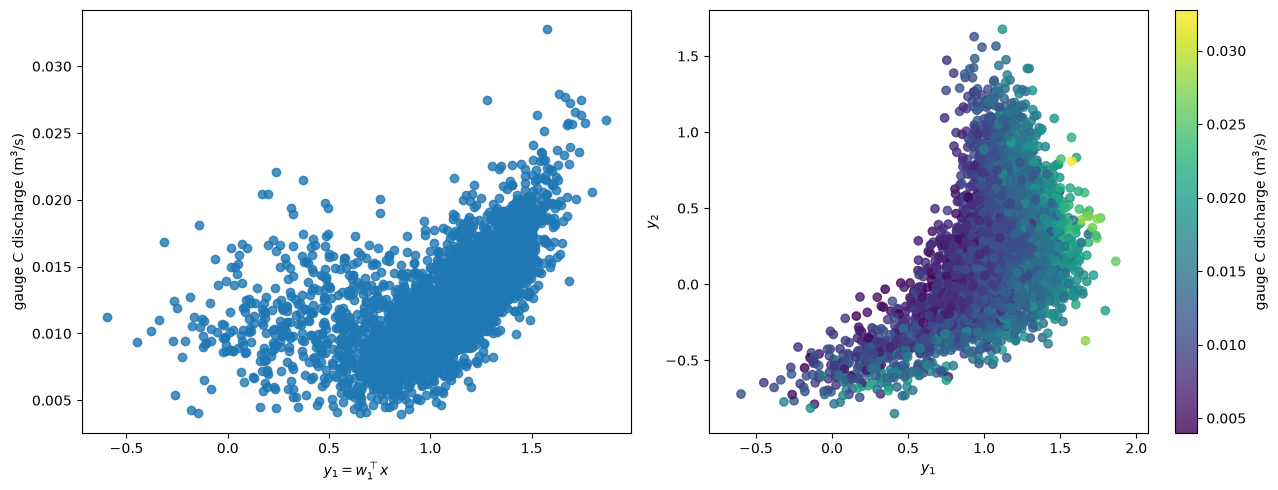

In [12]:
fG = Y[acc, 1]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ac.plotting.plot_sufficient_summary(sub, X=Za, f=fG, dims=1, qoi_label='gauge C discharge (m$^3$/s)', ax=axes[0])
ac.plotting.plot_sufficient_summary(sub, X=Za, f=fG, dims=2, qoi_label='gauge C discharge (m$^3$/s)', ax=axes[1])
fig.tight_layout()
y = Xa @ sub.W1
print(f'NSE of a cubic in y1: {cubic_nse(y[:, :1], fG):.3f}; in (y1, y2): {cubic_nse(y, fG):.3f} '
      f'(paper Fig. 6: 0.67)')
plt.close(fig)
fig

The one-dimensional summary plot shows a clear trend with wide scatter; a cubic in $y_1$ has NSE 0.532. A cubic in $(y_1, y_2)$ reaches 0.672, the paper's 0.67 in Fig. 6, so the second active variable carries real structure, which supports the paper's choice of $n = 2$ over the gap rule's $n = 1$.

NSE of a cubic in (y1, y2): 0.753 (paper Fig. 6: 0.75); |w1(gauge C) . w1(net)| = 0.898


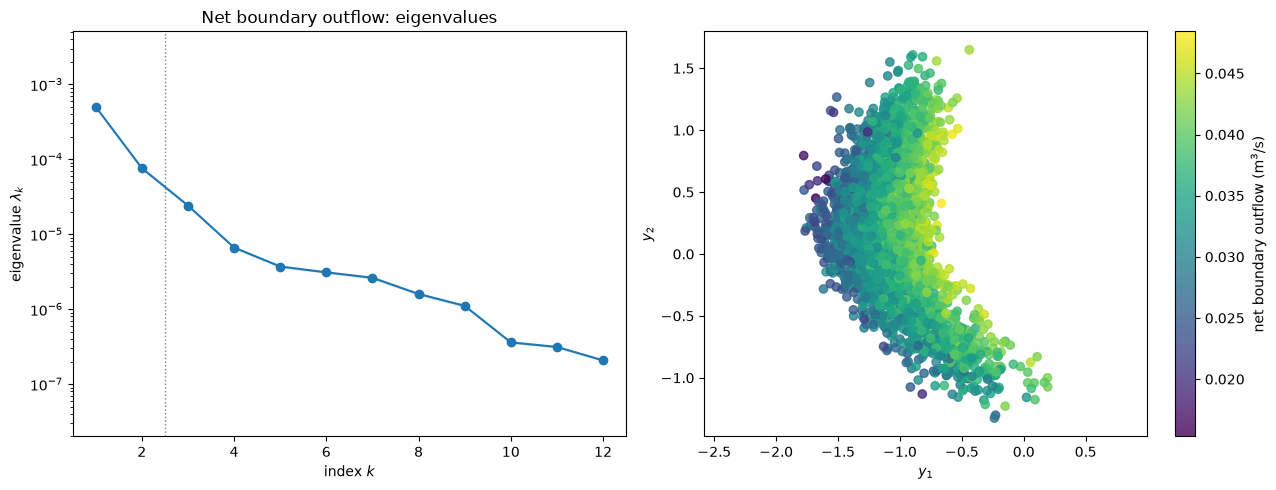

In [13]:
subN = subs['net_boundary_outflow']
fN = Y[acc, 5]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ac.plotting.plot_eigenvalues(subN, k_max=12, ax=axes[0])
axes[0].set_title('Net boundary outflow: eigenvalues')
ac.plotting.plot_sufficient_summary(subN, X=Za, f=fN, dims=2, qoi_label='net boundary outflow (m$^3$/s)', ax=axes[1])
fig.tight_layout()
yN = Xa @ subN.W1
print(f'NSE of a cubic in (y1, y2): {cubic_nse(yN, fN):.3f} (paper Fig. 6: 0.75); '
      f'|w1(gauge C) . w1(net)| = {abs(sub.W[:, 0] @ subN.W[:, 0]):.3f}')
plt.close(fig)
fig

For the net boundary outflow, $\lambda_1/\lambda_2 = 6.60$ and $\lambda_2/\lambda_3 = 3.15$ (92.8% of the trace in two eigenvalues), and the cubic meta-model in $(y_1, y_2)$ has NSE 0.753 (paper Fig. 6: 0.75). Its first direction is close to that of the gauge-C discharge, $|\mathbf w_1\cdot\mathbf w_1'| = 0.898$: the two flows are two sides of the same partitioning of recharge. With the quadratic refitted, the 95% interval of $\lambda_1/\lambda_2$ is [5.87, 7.32] and the mean distance of the two-dimensional subspace is 0.0602 (quadratic fixed: [6.20, 6.96] and 0.0141).

### Activity scores and the paper's Figs. 6 and 9

The paper plots $\sqrt{a_i}$ with $n=2$. Our values, with inputs on $[-1,1]$ (Eq. 4), match Fig. 9 directly but are half of those in Fig. 6. The supplement's app explains why: it rescales the stored $u$ to $[-1,1]$ only if their overall mean is within 0.01 of 0.5, and over the behavioral runs the mean is 0.4851, so the app used $u\in[0,1]$, which doubles every gradient and $\sqrt{a_i}$. Figs. 6 and 8 used $[0,1]$; Fig. 9 used $[-1,1]$. The table gives both scalings. Paper values are read from the figures. Because the scores alone cannot exclude other explanations of a factor of 2, the cell also prints the ranges of the active variables, which the axes of Fig. 6's scatter plots show directly.

input                   gauge C [-1,1]  x2 = [0,1]  Fig. 6    net [-1,1]  x2 = [0,1]  Fig. 6
K_km1w                          0.0090      0.0179  0.0180        0.0153      0.0305  0.0300
K_mo                            0.0104      0.0208  0.0210        0.0126      0.0252  0.0255
bottom_head_offset              0.0058      0.0117  0.0120        0.0071      0.0142  0.0145
K_ku                            0.0056      0.0112  0.0118        0.0064      0.0129  0.0132
fault_offset                    0.0048      0.0097  0.0098        0.0060      0.0120  0.0125
cauchy_head                     0.0004      0.0007  0.0010        0.0041      0.0082  0.0085
recharge_crop                   0.0008      0.0016  0.0015        0.0035      0.0069  0.0072
largest |[0,1] value - Fig. 6| over the 14 values: 0.0006
discharge_gauge_C, inputs on [0,1] (stored u): y1 [-0.06, 1.17], y2 [-0.68, 0.58]   (each up to sign; Fig. 6 about [-0.07, 1.17], [-0.58, 0.68])
discharge_gauge_C, inputs on [-1,1] (2u - 1) : y1 [-0

net_boundary_outflow, inputs on [0,1] (stored u): y1 [-0.04, 0.94], y2 [-0.49, 1.00]   (each up to sign; Fig. 6 about [-0.93, 0.02], [-0.98, 0.48])
net_boundary_outflow, inputs on [-1,1] (2u - 1) : y1 [-0.19, 1.78], y2 [-1.33, 1.65]   (each up to sign; Fig. 6 about [-0.93, 0.02], [-0.98, 0.48])
ranking, gauge C: K_mo, K_km1w, bottom_head_offset, K_ku, fault_offset, recharge_grass, aniso_ku
ranking, net    : K_km1w, K_mo, bottom_head_offset, K_ku, fault_offset, cauchy_head, recharge_crop
largest sqrt score among alpha, n and Ss (15 inputs), gauge C: 2.29e-04 (top input 1.04e-02)


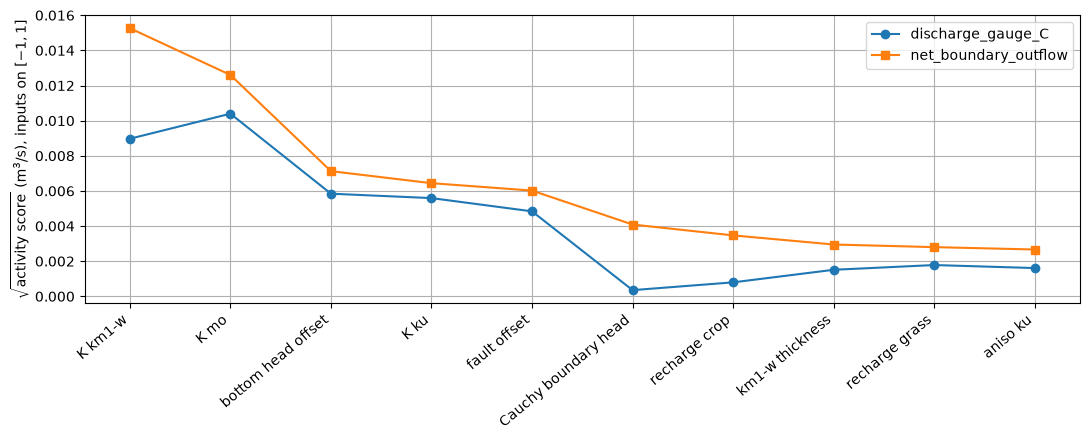

In [14]:
# sqrt activity scores with n = 2 (Eq. 8). The paper's Fig. 6 values (read from the figure)
# match inputs scaled to [0, 1], which doubles sqrt(a); Fig. 9 matches [-1, 1] (see text).
paper_fig6 = {  # input index: (gauge C, net boundary), m^3/s, read from Fig. 6
    4: (0.018, 0.030), 10: (0.021, 0.0255), 0: (0.012, 0.0145), 6: (0.0118, 0.0132),
    1: (0.0098, 0.0125), 28: (0.001, 0.0085), 29: (0.0015, 0.0072)}
sa = {nm: np.sqrt(ac.activity_scores(s, 2)) for nm, s in subs.items()}
print(f"{'input':22s} {'gauge C [-1,1]':>15s} {'x2 = [0,1]':>11s} {'Fig. 6':>7s}   "
      f"{'net [-1,1]':>11s} {'x2 = [0,1]':>11s} {'Fig. 6':>7s}")
for j, (pg, pn) in paper_fig6.items():
    a, b = sa['discharge_gauge_C'][j], sa['net_boundary_outflow'][j]
    print(f'{ki.NAMES[j]:22s} {a:15.4f} {2 * a:11.4f} {pg:7.4f}   {b:11.4f} {2 * b:11.4f} {pn:7.4f}')
dif = [abs(2 * sa[nm][j] - p[i]) for j, p in paper_fig6.items()
       for i, nm in enumerate(['discharge_gauge_C', 'net_boundary_outflow'])]
print(f'largest |[0,1] value - Fig. 6| over the 14 values: {max(dif):.4f}')
# The axes of Fig. 6's scatter plots tell the two scalings apart: active-variable ranges (min, max).
fig6_axes = {'discharge_gauge_C': ((-0.07, 1.17), (-0.58, 0.68)), 'net_boundary_outflow': ((-0.93, 0.02), (-0.98, 0.48))}
for nm, k in qois.items():
    for lab, Xs in [('[0,1] (stored u)', Ua), ('[-1,1] (2u - 1)', 2 * Ua - 1)]:
        G, _ = fit_gradients(Xs, Y[acc, k], 1)
        lam, W = eig_C(G)
        y = Xs @ W[:, :2]
        print(f'{nm}, inputs on {lab:16s}: y1 [{y[:, 0].min():.2f}, {y[:, 0].max():.2f}], '
              f'y2 [{y[:, 1].min():.2f}, {y[:, 1].max():.2f}]   (each up to sign; Fig. 6 about '
              f'{list(fig6_axes[nm][0])}, {list(fig6_axes[nm][1])})')
order = np.argsort(-sa['net_boundary_outflow'])[:10]
fig, ax = plt.subplots(figsize=(11, 4.5))
for nm, mk in [('discharge_gauge_C', 'o-'), ('net_boundary_outflow', 's-')]:
    ax.plot(range(10), sa[nm][order], mk, label=nm)
ax.set_xticks(range(10))
ax.set_xticklabels([ki.LABELS[j] for j in order], rotation=40, ha='right')
ax.set_ylabel(r'$\sqrt{\mathrm{activity\ score}}$ (m$^3$/s), inputs on $[-1,1]$')
ax.grid(True)
ax.legend()
fig.tight_layout()
print('ranking, gauge C:', ', '.join(ki.NAMES[j] for j in np.argsort(-sa['discharge_gauge_C'])[:7]))
print('ranking, net    :', ', '.join(ki.NAMES[j] for j in order[:7]))
print(f'largest sqrt score among alpha, n and Ss (15 inputs), gauge C: '
      f'{sa["discharge_gauge_C"][12:27].max():.2e} (top input {sa["discharge_gauge_C"].max():.2e})')
plt.close(fig)
fig

With the $[0,1]$ scaling, all fourteen values agree with Fig. 6 within 0.0006 m$^3$/s, about the precision of reading the figure (largest for the Lettenkeuper conductivity, gauge C: 0.0112 against about 0.0118). The scatter-plot axes confirm the scaling: with inputs on $[0,1]$ the gauge-C active variables span $y_1\in[-0.06, 1.17]$ and $y_2\in[-0.68, 0.58]$ (each up to sign; Fig. 6 about $[-0.07, 1.17]$ and $[-0.58, 0.68]$), against $[-0.60, 1.87]$ and $[-1.68, 0.85]$ with inputs on $[-1,1]$; the net outflow agrees in the same way ($[-0.04, 0.94]$ and $[-0.49, 1.00]$, Fig. 6 about $[-0.93, 0.02]$ and $[-0.98, 0.48]$ with the opposite signs). The ranking is the paper's: for gauge C, Muschelkalk conductivity, weathered-Gipskeuper conductivity, bottom head offset, Lettenkeuper conductivity and fault offset; for the net outflow the first two swap. Recharge matters little (the paper's point on p. 3797), and the fifteen van Genuchten and specific-storage inputs have $\sqrt{a_i}$ at most 2.29e-4 m$^3$/s against 1.04e-2 for the top input, as expected at steady state.

**The paper's Fig. 9: dependence on the gradient fit.** The paper drew 2,500 of the behavioral runs without replacement 1,000 times and recomputed the activity scores and the meta-model NSE with each of the three gradient fits (p. 3799). We repeat this 500 times. The linear fit gives a constant gradient, hence one active variable, and its meta-model is a cubic in $y_1$.

500 repetitions in 28 s
full second-order             NSE 2.5-97.5%: [0.654, 0.690], median 0.673, min-max [0.647, 0.704]
    sqrt activity (median, x1e-3): K_mo 10.40, K_km1w 9.03, bottom_head_offset 5.85, K_ku 5.62, fault_offset 4.85, recharge_grass 1.78, km1w_thickness 1.55
second-order, no cross terms  NSE 2.5-97.5%: [0.565, 0.609], median 0.588, min-max [0.551, 0.617]
    sqrt activity (median, x1e-3): K_mo 7.65, K_km1w 6.69, bottom_head_offset 3.93, K_ku 0.97, fault_offset 2.36, recharge_grass 1.54, km1w_thickness 0.57
linear                        NSE 2.5-97.5%: [0.457, 0.506], median 0.483, min-max [0.442, 0.517]
    sqrt activity (median, x1e-3): K_mo 2.47, K_km1w 4.43, bottom_head_offset 2.62, K_ku 0.85, fault_offset 1.36, recharge_grass 1.41, km1w_thickness 0.27


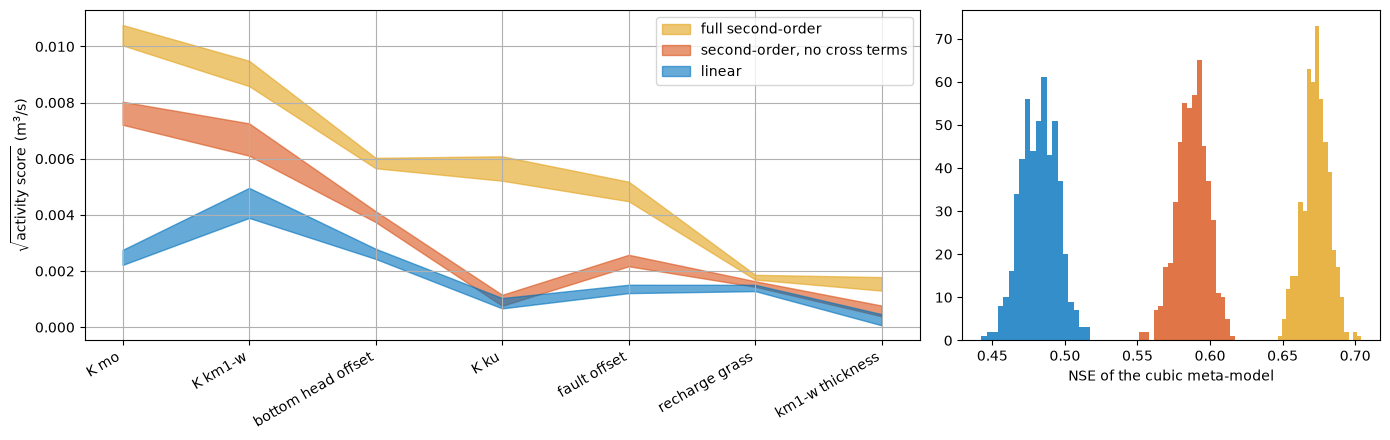

In [15]:
# Paper Sect. 4.3 and Fig. 9: 2500 of the behavioral runs drawn without replacement, the
# gradient fit refitted, activity scores and the meta-model NSE recomputed; 500 repetitions.
rng = np.random.default_rng(SEED)
B, fGa = 500, Y[acc, 1]
top7 = [10, 4, 0, 6, 1, 30, 3]          # the seven inputs of Fig. 9, in its order
S = np.empty((3, B, m)); N = np.empty((3, B))
t0 = time.perf_counter()
for b in range(B):
    idx = rng.choice(acc.sum(), 2500, replace=False)
    for i, fit in enumerate((1, 2, 3)):
        G, _ = fit_gradients(Xa[idx], fGa[idx], fit)
        lam, W = eig_C(G)
        n = 1 if fit == 3 else 2
        S[i, b] = np.sqrt((W[:, :n] ** 2) @ lam[:n])
        N[i, b] = cubic_nse(Xa[idx] @ W[:, :n], fGa[idx])
print(f'{B} repetitions in {time.perf_counter() - t0:.0f} s')
names_fit = ['full second-order', 'second-order, no cross terms', 'linear']
for i in range(3):
    print(f'{names_fit[i]:29s} NSE 2.5-97.5%: [{np.percentile(N[i], 2.5):.3f}, {np.percentile(N[i], 97.5):.3f}], '
          f'median {np.median(N[i]):.3f}, min-max [{N[i].min():.3f}, {N[i].max():.3f}]')
    print('    sqrt activity (median, x1e-3): ' + ', '.join(f'{ki.NAMES[j]} {1e3 * np.median(S[i, :, j]):.2f}' for j in top7))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={'width_ratios': [2, 1]})
cols = ['#e3a21a', '#d95319', '#0072bd']
for i in range(3):
    q = np.percentile(S[i][:, top7], [2.5, 97.5], axis=0)
    axes[0].fill_between(range(7), q[0], q[1], color=cols[i], alpha=0.6, label=names_fit[i])
    axes[1].hist(N[i], bins=20, color=cols[i], alpha=0.8)
axes[0].set_xticks(range(7))
axes[0].set_xticklabels([ki.LABELS[j] for j in top7], rotation=30, ha='right')
axes[0].set_ylabel(r'$\sqrt{\mathrm{activity\ score}}$ (m$^3$/s)')
axes[0].legend()
axes[0].grid(True)
axes[1].set_xlabel('NSE of the cubic meta-model')
fig.tight_layout()
plt.close(fig)
fig

The NSE ranges match the histograms of Fig. 9 for the two quadratic fits: 0.654–0.690 for the full quadratic (Fig. 9: about 0.66–0.70) and 0.565–0.609 without cross terms (about 0.57–0.61). For the linear fit we get 0.457–0.506 (largest of the 500 values 0.517), while the paper's blue histogram has visible bins from about 0.45 to 0.56: its upper tail is heavier than ours. The median scores of the full quadratic, 10.40e-3 (Muschelkalk) and 9.03e-3 (weathered Gipskeuper) down to 1.55e-3 (weathering-zone thickness), fall in the bands of Fig. 9, and, as the paper notes, dropping the cross terms lowers every score, most of all the Lettenkeuper conductivity (from 5.62e-3 to 0.97e-3). These intervals include refitting the quadratic, but they are the spread of estimates from $M$ = 2,500 runs drawn without replacement (the paper's design), not the uncertainty of the 4,528-run estimate; for that, see the refit bootstrap above.

### Residence times and the paper's Fig. 8

The authors do not state the unit of the stored residence times. Fig. 8 (p. 3799) is in years, and its colour bars, like those of Fig. 6, run from the smallest to the largest plotted (behavioral) value. The stored values divided by 17,520 reproduce the ends of all three bars; divided by 8,760 (hours per year) they are twice as large. We therefore convert with years = stored / 17,520 (`ki.RESIDENCE_PER_YEAR`), which would make the stored unit half-hours (17,520 per 365-day year). That unit is an inference from the figure, not a stated fact; the stored values are not changed. Fig. 8 also used inputs on $[0,1]$ (the stored $u$), as Fig. 6 did. The activity scores cannot tell the two readings apart (inputs on $[0,1]$ double $\sqrt{a}$, and dividing by 17,520 instead of 8,760 halves it, so both give the same numbers), but the colour bars and the active-variable ranges of the scatter plots can; the cell prints both readings.

In [16]:
# Fig. 8 used inputs on [0, 1] (the stored u, Eq. 4 not applied) and years = stored / 17,520.
paper_fig8 = {6: ('ku', 0.87, {1: 33.5, 6: 31.0, 2: 21.5, 3: 14.5}),
              7: ('km1', 0.87, {3: 168.0, 4: 120.0, 8: 107.0, 2: 75.0}),
              8: ('km1-w', 0.31, {})}
fig8_bar = {6: (0.3, 79.5), 7: (0.5, 305.0), 8: (2.2, 37.7)}                  # colour-bar ends, yr
fig8_axes = {6: ((-0.5, 0.9), (-0.5, 0.78)), 7: ((-0.1, 0.97), (-0.28, 1.28)),  # scatter-plot axes
             8: ((-0.38, 0.78), (-0.55, 0.62))}
for k, (unit, pn, pa) in paper_fig8.items():
    raw = Y[acc, k]
    f = raw / STORED_PER_YEAR                            # years, on the paper's Fig. 8 scale
    print(f'residence time in {unit}: behavioral range stored/17520 = [{f.min():.2f}, {f.max():.1f}] yr, '
          f'stored/8760 = [{raw.min() / 8760:.2f}, {raw.max() / 8760:.1f}]; Fig. 8 colour bar about '
          f'[{fig8_bar[k][0]}, {fig8_bar[k][1]}]')
    for lab, Xs, ff in [('[0,1], stored/17520', Ua, f), ('[-1,1], stored/8760', 2 * Ua - 1, raw / 8760)]:
        G, r2 = fit_gradients(Xs, ff, 1)
        lam, W = eig_C(G)
        y = Xs @ W[:, :2]
        s = np.sqrt((W[:, :2] ** 2) @ lam[:2])
        print(f'    inputs {lab}: y1 [{y[:, 0].min():.2f}, {y[:, 0].max():.2f}], y2 [{y[:, 1].min():.2f}, '
              f'{y[:, 1].max():.2f}] (up to sign; Fig. 8 about {list(fig8_axes[k][0])}, {list(fig8_axes[k][1])})'
              + ('; sqrt activity (yr): ' + ', '.join(f'{ki.NAMES[j]} {s[j]:.1f}' for j in pa) if pa else ''))
    G, r2 = fit_gradients(Ua, f, 1)
    lam, W = eig_C(G)
    s = np.sqrt((W[:, :2] ** 2) @ lam[:2])
    print(f'    median {np.median(f):.1f} yr; NSE (cubic in y1, y2) {cubic_nse(Ua @ W[:, :2], f):.3f} '
          f'(Fig. 8: {pn}); lambda1/lambda2 = {lam[0] / lam[1]:.2f}')
    if pa:
        print('    sqrt activity (yr), here vs Fig. 8: ' +
              ', '.join(f'{ki.NAMES[j]} {s[j]:.1f} vs {v:g}' for j, v in pa.items()))
        print('    top four here: ' + ', '.join(ki.NAMES[j] for j in np.argsort(-s)[:4]))

residence time in ku: behavioral range stored/17520 = [0.24, 79.1] yr, stored/8760 = [0.47, 158.3]; Fig. 8 colour bar about [0.3, 79.5]
    inputs [0,1], stored/17520: y1 [-0.50, 0.90], y2 [-0.52, 0.79] (up to sign; Fig. 8 about [-0.5, 0.9], [-0.5, 0.78]); sqrt activity (yr): fault_offset 34.1, K_ku 30.8, contact_offset_ku_km1 21.3, km1w_thickness 13.9


    inputs [-1,1], stored/8760: y1 [-1.02, 1.78], y2 [-1.98, 0.65] (up to sign; Fig. 8 about [-0.5, 0.9], [-0.5, 0.78]); sqrt activity (yr): fault_offset 34.1, K_ku 30.8, contact_offset_ku_km1 21.3, km1w_thickness 13.9
    median 12.8 yr; NSE (cubic in y1, y2) 0.871 (Fig. 8: 0.87); lambda1/lambda2 = 11.27
    sqrt activity (yr), here vs Fig. 8: fault_offset 34.1 vs 33.5, K_ku 30.8 vs 31, contact_offset_ku_km1 21.3 vs 21.5, km1w_thickness 13.9 vs 14.5
    top four here: fault_offset, K_ku, contact_offset_ku_km1, km1w_thickness
residence time in km1: behavioral range stored/17520 = [0.51, 303.6] yr, stored/8760 = [1.03, 607.2]; Fig. 8 colour bar about [0.5, 305.0]
    inputs [0,1], stored/17520: y1 [-0.11, 0.97], y2 [-1.28, 0.28] (up to sign; Fig. 8 about [-0.1, 0.97], [-0.28, 1.28]); sqrt activity (yr): km1w_thickness 168.9, K_km1w 119.0, K_km1 106.0, contact_offset_ku_km1 71.5


    inputs [-1,1], stored/8760: y1 [-1.24, 0.91], y2 [-2.06, 1.06] (up to sign; Fig. 8 about [-0.1, 0.97], [-0.28, 1.28]); sqrt activity (yr): km1w_thickness 168.9, K_km1w 119.0, K_km1 106.0, contact_offset_ku_km1 71.5
    median 48.2 yr; NSE (cubic in y1, y2) 0.870 (Fig. 8: 0.87); lambda1/lambda2 = 10.42
    sqrt activity (yr), here vs Fig. 8: km1w_thickness 168.9 vs 168, K_km1w 119.0 vs 120, K_km1 106.0 vs 107, contact_offset_ku_km1 71.5 vs 75
    top four here: km1w_thickness, K_km1w, K_km1, contact_offset_ku_km1
residence time in km1-w: behavioral range stored/17520 = [2.13, 37.6] yr, stored/8760 = [4.27, 75.2]; Fig. 8 colour bar about [2.2, 37.7]
    inputs [0,1], stored/17520: y1 [-0.40, 0.78], y2 [-0.61, 0.55] (up to sign; Fig. 8 about [-0.38, 0.78], [-0.55, 0.62])
    inputs [-1,1], stored/8760: y1 [-1.28, 1.07], y2 [-1.40, 0.93] (up to sign; Fig. 8 about [-0.38, 0.78], [-0.55, 0.62])


    median 10.9 yr; NSE (cubic in y1, y2) 0.315 (Fig. 8: 0.31); lambda1/lambda2 = 1.35


On the paper's scale the behavioral residence times span 0.24–79.1 yr (ku), 0.51–303.6 yr (km1) and 2.13–37.6 yr (km1-w), the ends of Fig. 8's colour bars (about 0.3–79.5, 0.5–305 and 2.2–37.7 yr); stored/8,760 would put the tops at 158.3, 607.2 and 75.2 yr, twice the bars. With inputs on $[0,1]$ the active variables span the axes of Fig. 8's scatter plots (ku: $y_1\in[-0.50, 0.90]$, $y_2\in[-0.52, 0.79]$ against about $[-0.5, 0.9]$ and $[-0.5, 0.78]$; km1: $[-0.11, 0.97]$ and, up to sign, $[-0.28, 1.28]$, as in the figure), while inputs on $[-1,1]$ give about twice the spread (ku $y_1\in[-1.02, 1.78]$). The median residence times are 12.8 yr (ku), 48.2 yr (km1) and 10.9 yr (km1-w). The NSE values, 0.871, 0.870 and 0.315, match Fig. 8 (0.87, 0.87, 0.31), and the four leading scores agree within 0.6 yr for the Lettenkeuper and within 3.5 yr (contact offset, 71.5 against about 75) for the Gipskeuper, in the paper's order. These targets have larger gaps ($\lambda_1/\lambda_2$ = 11.27 and 10.42), except the weathering zone (1.35), where the paper also finds no useful subspace.

### A surrogate on the active variables

The paper's meta-model is a cubic in the active variables. v1's `fit_surrogate` fits the same polynomial and gives a leave-one-out $R^2$ (with $\mathbf W_1$ fixed from all behavioral runs).

discharge_gauge_C: degree-3 polynomial in 1 active variable(s): in-sample R^2 (NSE) 0.532, LOO R^2 0.531
discharge_gauge_C: degree-3 polynomial in 2 active variable(s): in-sample R^2 (NSE) 0.672, LOO R^2 0.670
net_boundary_outflow: degree-3 polynomial in 1 active variable(s): in-sample R^2 (NSE) 0.521, LOO R^2 0.520
net_boundary_outflow: degree-3 polynomial in 2 active variable(s): in-sample R^2 (NSE) 0.753, LOO R^2 0.752


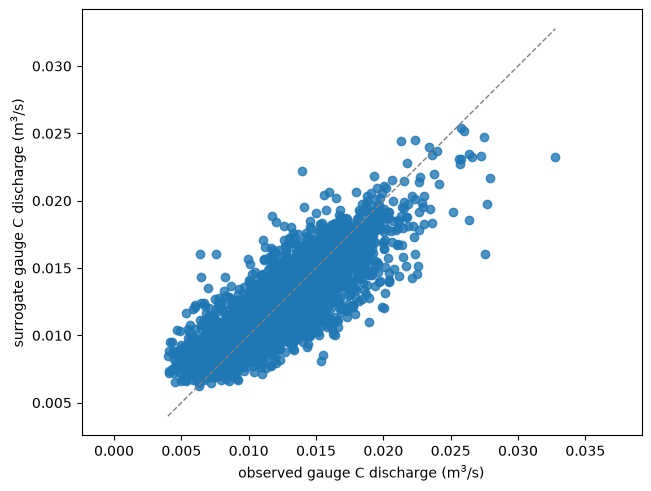

In [17]:
for name, k in qois.items():
    f = Y[acc, k]
    for n, deg in [(1, 3), (2, 3)]:
        s = ac.fit_surrogate(X=Za, f=f, space=space, subspace=ac.with_dimension(subs[name], n),
                             kind='poly', degree=deg)
        r2 = 1 - np.sum(s.residuals ** 2) / np.sum((f - f.mean()) ** 2)
        print(f'{name}: degree-{deg} polynomial in {n} active variable(s): in-sample R^2 (NSE) {r2:.3f}, '
              f'LOO R^2 {s.loo_r_squared:.3f}')
sur = ac.fit_surrogate(X=Za, f=fG, space=space, subspace=sub, kind='poly', degree=3)
fig, ax = ac.plotting.plot_surrogate_fit(sur, X=Za, f=fG, qoi_label='gauge C discharge (m$^3$/s)')
plt.close(fig)
fig

The leave-one-out $R^2$ equals the in-sample value to within 0.002 (gauge C: 0.670 against 0.672 with two active variables; 0.531 with one), so ten coefficients on 4,528 runs do not overfit. About a third of the variance of the gauge-C discharge remains outside the two-dimensional cubic; a third active variable or a richer surrogate would be needed to explain it.

### Does the density matter?

Two checks of how much the results depend on the behavioral sample: (a) v1's `"qphd"`, which fits the same kind of quadratic but averages over the uniform box; (b) the gradient estimator on all 10,050 runs.

In [18]:
# (a) QPHD: the same quadratic, but C = g g^T + H Sigma H with Sigma the covariance of the
#     uniform box (Sigma = I/3), i.e. averaged over the prior instead of the behavioral runs.
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always', ac.ValidityWarning)
    q = ac.active_subspace(space=space, X=Za, f=fG, estimator='qphd', n=2)
print('warning:', '; '.join(str(w.message)[:100] for w in caught))
d = lambda A, B: np.linalg.norm(A.W1.T @ B.W2, 2)
sa_q = np.sqrt(ac.activity_scores(q, 2))
print(f'QPHD (prior average): lambda1/lambda2 = {q.eigenvalues[0] / q.eigenvalues[1]:.2f}; distance to the '
      f'behavioral 2-D subspace {d(sub, q):.3f}; top inputs ' +
      ', '.join(f'{ki.NAMES[j]} {sa_q[j]:.4f}' for j in np.argsort(-sa_q)[:5]))
# (b) the same estimator on all 10050 runs (the adaptive sample, behavioral or not)
Gall, _ = fit_gradients(Xn, Y[:, 1], 1)
sub_all = ac.active_subspace(space=space, X=Z, grads=Gall / half, estimator='as', n=2)
sa_all = np.sqrt(ac.activity_scores(sub_all, 2))
print(f'all 10050 runs: lambda1/lambda2 = {sub_all.eigenvalues[0] / sub_all.eigenvalues[1]:.2f}; distance to '
      f'the behavioral subspace {d(sub, sub_all):.3f}; top inputs ' +
      ', '.join(f'{ki.NAMES[j]} {sa_all[j]:.4f}' for j in np.argsort(-sa_all)[:5]))
print(f'Total run time: {time.perf_counter() - t_start:.0f} s')

QPHD (prior average): lambda1/lambda2 = 4.91; distance to the behavioral 2-D subspace 0.590; top inputs K_ku 0.0112, fault_offset 0.0108, km1w_thickness 0.0080, K_mo 0.0071, K_km1w 0.0053


all 10050 runs: lambda1/lambda2 = 6.24; distance to the behavioral subspace 0.258; top inputs K_mo 0.0086, K_km1w 0.0078, bottom_head_offset 0.0051, fault_offset 0.0044, K_ku 0.0035
Total run time: 79 s


It matters. Averaged over the uniform box, the quadratic fitted to the behavioral runs gives a two-dimensional subspace at distance 0.590 from the behavioral one, led by the Lettenkeuper conductivity and the fault offset; this extrapolates the quadratic into regions with almost no runs (only 10 of the 500 Latin hypercube runs are behavioral), so it should not be read as the prior's subspace. Using all 10,050 runs, which still oversample the behavioral region, moves the subspace by 0.258 and keeps the same leading inputs. The active subspace reported here, like the paper's, is a statement about the behavioral region of the parameter space.

### Comparison with the paper

Paper values marked "Fig." are read from the figures.

| Quantity | Paper | This notebook |
|---|---|---|
| Behavioral (stage-two) runs | 4,533 of 10,000 | 4,528 of 10,050 (no subset of the stored runs gives 4,533) |
| Fig. 4 NSE, first 500 runs (flooding, ratio, stream A) | 0.76, 0.75, 0.56 | 0.762, 0.748, 0.561 |
| Fig. 4 NSE, first 1000 runs | 0.83, 0.72, 0.65 | 0.825, 0.715, 0.655 |
| Fig. 4 NSE, all runs | 0.81, 0.74, 0.70 | 0.812, 0.745, 0.699 |
| Eigenvalues, gauge C | not reported | $\lambda_1/\lambda_2$ = 4.62 (refit 95%: [4.07, 5.28]), $\lambda_2/\lambda_3$ = 3.18 ([2.54, 3.75]) |
| Eigenvalues, net boundary outflow | not reported | 6.60 ([5.87, 7.32]), 3.15 |
| Meta-model NSE, gauge C / net outflow (Fig. 6) | 0.67 / 0.75 | 0.672 / 0.753 |
| $\sqrt{a}$ gauge C, K mo and K km1-w (Fig. 6, $[0,1]$ scaling) | about 0.021, 0.018 | 0.0208, 0.0179 |
| $\sqrt{a}$ net outflow, K km1-w and K mo (Fig. 6) | about 0.030, 0.0255 | 0.0305, 0.0252 |
| Fig. 6 active-variable ranges, gauge C ($[0,1]$ inputs) | about $[-0.07, 1.17]$, $[-0.58, 0.68]$ | $[-0.06, 1.17]$, $[-0.68, 0.58]$ (up to sign) |
| Fig. 9 NSE, full / no cross terms / linear | about 0.66–0.70 / 0.57–0.61 / 0.45–0.56 | 0.654–0.690 / 0.565–0.609 / 0.457–0.506 (95%) |
| Fig. 9 $\sqrt{a}$, K mo, full quadratic ($[-1,1]$) | about 0.010–0.011 | median 0.0104 |
| Fig. 8 colour-bar range, residence time ku / km1 / km1-w (yr) | about 0.3–79.5 / 0.5–305 / 2.2–37.7 | 0.24–79.1 / 0.51–303.6 / 2.13–37.6 (stored / 17,520) |
| Fig. 8 NSE, residence time ku / km1 / km1-w | 0.87 / 0.87 / 0.31 | 0.871 / 0.870 / 0.315 |
| Fig. 8 $\sqrt{a}$, ku: fault offset, K ku (yr; $[0,1]$ inputs) | about 33.5, 31 | 34.1, 30.8 |
| Fig. 8 $\sqrt{a}$, km1: km1-w thickness, K km1-w (yr) | about 168, 120 | 168.9, 119.0 |
| Leave-one-out $R^2$ of the cubic in $(y_1,y_2)$, gauge C | not reported | 0.670 |

The stored runs reproduce every published number we could check, given two facts the paper does not state: Figs. 6 and 8 use inputs on $[0,1]$ (Fig. 9 uses $[-1,1]$), and Fig. 8's years are the stored residence times divided by 17,520. The linear-fit NSE histogram of Fig. 9 has a heavier upper tail than ours. The open points are the five-run difference in the behavioral count, the 50 rows beyond the paper's 10,000 and the unit of the stored residence times; none changes a reported value at the printed precision.

### References

[1] D. Erdal and O. A. Cirpka. Global sensitivity analysis and adaptive stochastic sampling of a subsurface-flow model using active subspaces. *Hydrology and Earth System Sciences* 23(9):3787–3805, 2019. [doi:10.5194/hess-23-3787-2019](https://doi.org/10.5194/hess-23-3787-2019). Data: the article's supplement, [doi:10.5194/hess-23-3787-2019-supplement](https://doi.org/10.5194/hess-23-3787-2019-supplement) (CC BY 4.0).

[2] P. G. Constantine. *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*. SIAM, Philadelphia, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860)

[3] P. G. Constantine, E. Dow and Q. Wang. Active subspace methods in theory and practice: applications to kriging surfaces. *SIAM Journal on Scientific Computing* 36(4):A1500–A1524, 2014. [doi:10.1137/130916138](https://doi.org/10.1137/130916138)

[4] P. G. Constantine and P. Diaz. Global sensitivity metrics from active subspaces. *Reliability Engineering & System Safety* 162:1–13, 2017. [doi:10.1016/j.ress.2017.01.013](https://doi.org/10.1016/j.ress.2017.01.013)

[5] Z. J. Grey and P. G. Constantine. Active subspaces of airfoil shape parameterizations. *AIAA Journal* 56(5):2003–2017, 2018. [doi:10.2514/1.J056054](https://doi.org/10.2514/1.J056054)

[6] K.-C. Li. On principal Hessian directions for data visualization and dimension reduction: another application of Stein's lemma. *Journal of the American Statistical Association* 87(420):1025–1039, 1992. [doi:10.1080/01621459.1992.10476258](https://doi.org/10.1080/01621459.1992.10476258)

[7] Aquanty Inc. *HydroGeoSphere User Manual*. Technical report, Aquanty Inc., Waterloo, ON, Canada, 2015.

### Acknowledgments

The paper's work was supported by the Collaborative Research Center 1253 CAMPOS (Project 7: Stochastic Modeling Framework of Catchment-Scale Reactive Transport), funded by the German Research Foundation (DFG; grant agreement SFB 1253/1) [1].